In [ ]:
## import libraries

In [ ]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
## load dataset

In [ ]:
df = pd.read_csv("AirQualityUCI.csv", sep=";", decimal=",", na_values=-200)

In [ ]:
## print first 5 rows

In [ ]:
print("First 5 rows:")
print(df.head())

First 5 rows:
         Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
0  10/03/2004  18.00.00     2.6       1360.0     150.0      11.9   
1  10/03/2004  19.00.00     2.0       1292.0     112.0       9.4   
2  10/03/2004  20.00.00     2.2       1402.0      88.0       9.0   
3  10/03/2004  21.00.00     2.2       1376.0      80.0       9.2   
4  10/03/2004  22.00.00     1.6       1272.0      51.0       6.5   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0         1046.0    166.0        1056.0    113.0        1692.0       1268.0   
1          955.0    103.0        1174.0     92.0        1559.0        972.0   
2          939.0    131.0        1140.0    114.0        1555.0       1074.0   
3          948.0    172.0        1092.0    122.0        1584.0       1203.0   
4          836.0    131.0        1205.0    116.0        1490.0       1110.0   

      T    RH      AH  Unnamed: 15  Unnamed: 16  
0  13.6  48.9  0.7578          NaN          NaN  
1 

In [ ]:
## shape before preprocessing

In [ ]:
print("\nShape before preprocessing:", df.shape)


Shape before preprocessing: (9471, 17)


In [ ]:
## data preprocession

In [ ]:
df = df.drop_duplicates()
df = df.dropna(axis=1, how="all")
df = df.drop(["Date", "Time"], axis=1, errors="ignore")
df = df.apply(pd.to_numeric, errors="coerce")

print("\nMissing values:")
print(df.isnull().sum())


Missing values:
CO(GT)           1684
PT08.S1(CO)       367
NMHC(GT)         8444
C6H6(GT)          367
PT08.S2(NMHC)     367
NOx(GT)          1640
PT08.S3(NOx)      367
NO2(GT)          1643
PT08.S4(NO2)      367
PT08.S5(O3)       367
T                 367
RH                367
AH                367
dtype: int64


In [ ]:
## Fill missing values with median

In [ ]:
df = df.fillna(df.median())

print("\nFirst 5 rows after preprocessing:")
print(df.head())
print("\nShape after preprocessing:", df.shape)


First 5 rows after preprocessing:
   CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
0     2.6       1360.0     150.0      11.9         1046.0    166.0   
1     2.0       1292.0     112.0       9.4          955.0    103.0   
2     2.2       1402.0      88.0       9.0          939.0    131.0   
3     2.2       1376.0      80.0       9.2          948.0    172.0   
4     1.6       1272.0      51.0       6.5          836.0    131.0   

   PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)     T    RH      AH  
0        1056.0    113.0        1692.0       1268.0  13.6  48.9  0.7578  
1        1174.0     92.0        1559.0        972.0  13.3  47.7  0.7255  
2        1140.0    114.0        1555.0       1074.0  11.9  54.0  0.7502  
3        1092.0    122.0        1584.0       1203.0  11.0  60.0  0.7867  
4        1205.0    116.0        1490.0       1110.0  11.2  59.6  0.7888  

Shape after preprocessing: (9358, 13)


In [ ]:
## eda (historygram)

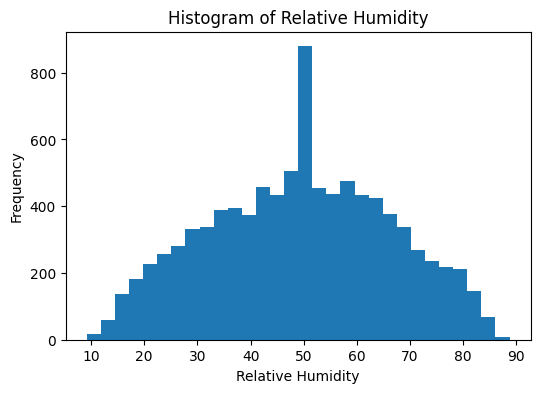

In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(df["RH"], bins=30)
plt.xlabel("Relative Humidity")
plt.ylabel("Frequency")
plt.title("Histogram of Relative Humidity")
plt.show()

In [ ]:
## select input-features

In [ ]:
X = df.drop("RH", axis=1)
y = df["RH"]

In [ ]:
## train test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# Handle missing values using training data

In [ ]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

In [ ]:
# Feature scaling

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
## model selection and pred.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
## regression evaluation

In [ ]:
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
R2 = r2_score(y_test, y_pred)

print("\nRegression Results")
print("MAE =", MAE)
print("MSE =", MSE)
print("RMSE =", RMSE)
print("R2 Score =", R2)


Regression Results
MAE = 4.51671967379351
MSE = 34.55454091403585
RMSE = 5.878311059652751
R2 Score = 0.8807491506108373


In [ ]:
# Actual vs predicted values

In [ ]:
print("\nActual RH:", y_test.iloc[:5].values)
print("Predicted RH:", y_pred[:5])


Actual RH: [55.3 23.5 43.6 56.2 56.5]
Predicted RH: [54.18720043 27.49093506 48.82944036 57.70806737 58.39177138]


In [ ]:
model_data = {
    "model": model,
    "imputer": imputer,
    "scaler": scaler,
    "features": X.columns.tolist()
}

with open("air_quality_model.pkl", "wb") as file:
    pickle.dump(model_data, file)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
!pip install fastapi uvicorn

In [ ]:
%%writefile app.py

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
import pickle
import pandas as pd

app = FastAPI()

# Load saved model
with open("air_quality_model.pkl", "rb") as file:
    data = pickle.load(file)

model = data["model"]
imputer = data["imputer"]
scaler = data["scaler"]
features = data["features"]

class AirQualityInput(BaseModel):
    values: dict[str, float]

@app.get("/")
def home():
    return {"message": "Air Quality Prediction API is running"}

@app.post("/predict")
def predict(input: AirQualityInput):

    missing = [f for f in features if f not in input.values]

    if missing:
        raise HTTPException(
            status_code=400,
            detail=f"Missing features: {missing}"
        )

    # Arrange input in training feature order
    df = pd.DataFrame(
        [[input.values[f] for f in features]],
        columns=features
    )

    # Preprocessing
    df = imputer.transform(df)
    df = scaler.transform(df)

    # Prediction
    prediction = model.predict(df)

    return {
        "Predicted RH": float(prediction[0])
    }

Writing app.py


In [ ]:
!uvicorn app:app --host 0.0.0.0 --port 8000 > /tmp/uvicorn.log 2>&1 &

In [ ]:
import requests

try:
    response = requests.get("http://127.0.0.1:8000", timeout=5)
    print("Status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Error:", e)

Error: HTTPConnectionPool(host='127.0.0.1', port=8000): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78a6e9d8d400>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
!cat /tmp/uvicorn.log

In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8000)"))

https://8000-m-s-usw1c9-d494ki6k9zhm-c.us-west1.prod.r.colab.dev


In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8000, height=800)

<IPython.core.display.Javascript object>

In [ ]:
output.serve_kernel_port_as_iframe(8000, path="/docs", height=800)

<IPython.core.display.Javascript object>